In [1]:
# Public Data Source Kaggle https://www.kaggle.com/datasets/imakash3011/customer-personality-analysis. Data Preparation, Preprocessing, and Validation. 
# Feature types, missing values provided
# Import necessary libraries.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# EDA
# Load dataset
df = pd.read_csv('marketing_campaign_aim.csv')
# Display first 5 rows
print(df.head())

# Dataset shape and info
print(f"Dataset Shape: {df.shape}")
print(df.info())

# Summary statistics
print(df.describe())

# Check for missing values
print(df.isnull().sum())

# Check for duplicates
duplicates = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicates}")

     ID  Year_Birth   Education Marital_Status   Income  Kidhome  Teenhome  \
0  5524        1957  Graduation         Single  58138.0        0         0   
1  2174        1954  Graduation         Single  46344.0        1         1   
2  4141        1965  Graduation       Together  71613.0        0         0   
3  6182        1984  Graduation       Together  26646.0        1         0   
4  5324        1981         PhD        Married  58293.0        1         0   

   Recency  MntWines  MntFruits  ...  NumWebVisitsMonth  AcceptedCmp3  \
0       58       635         88  ...                  7             0   
1       38        11          1  ...                  5             0   
2       26       426         49  ...                  4             0   
3       26        11          4  ...                  6             0   
4       94       173         43  ...                  5             0   

   AcceptedCmp4  AcceptedCmp5  AcceptedCmp1  AcceptedCmp2  Complain  \
0             0      

In [2]:
#Data Dictionary and limits

# 1. Specify the feature name and target range
filter_ranges = [
    ['Year_Birth',1920,2000],
    ['Income',0,120000],
    ['MntWines',0, 1000],
    ['MntFruits',0, 150],
    ['MntMeatProducts',0,1000],
    ['MntFishProducts',0,300],
    ['MntSweetProducts',0,300],
    ['MntGoldProds',0,400],
    ['NumDealsPurchases',0,30],
    ['NumWebPurchases',0,30],
    ['NumCatalogPurchases',0,30],
    ['NumStorePurchases',0,30],
    ['NumWebVisitsMonth',0,30]
         ]
  
# 2. Filter the entire DataFrame based on that specific feature
filtered_df=df.copy()
for feature,lower_limit,upper_limit in filter_ranges:
    filtered_df = filtered_df[filtered_df[feature].between(lower_limit, upper_limit)]

print(filtered_df)
filtered_df.describe()

         ID  Year_Birth   Education Marital_Status   Income  Kidhome  \
0      5524        1957  Graduation         Single  58138.0        0   
1      2174        1954  Graduation         Single  46344.0        1   
2      4141        1965  Graduation       Together  71613.0        0   
3      6182        1984  Graduation       Together  26646.0        1   
4      5324        1981         PhD        Married  58293.0        1   
...     ...         ...         ...            ...      ...      ...   
2213   8207        1957       Cycle        Married  53233.0        0   
2214   8722        1957       Cycle        Married  82347.0        0   
2215    607        1955       Cycle       Divorced  41769.0        0   
2216   3661        1995       Cycle         Single  80617.0        0   
2217  10659        1979       Cycle       Together   7500.0        1   

      Teenhome  Recency  MntWines  MntFruits  ...  NumWebVisitsMonth  \
0            0       58       635         88  ...              

,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
count,2038.000000,2038.000000,2038.000000,2038.000000,2038.000000,2038.000000,2038.000000,2038.000000,2038.000000,2038.000000,...,2038.000000,2038.000000,2038.000000,2038.000000,2038.000000,2038.000000,2038.000000,2038.0,2038.0,2038.000000
mean,5579.081943,1969.019627,49709.610402,0.471541,0.520608,49.216389,254.354760,21.726202,147.153582,34.161923,...,5.434740,0.069185,0.056428,0.046124,0.044161,0.006869,0.009814,3.0,11.0,0.129539
std,3268.377836,11.584638,20083.346665,0.542657,0.545718,29.044374,275.224786,31.839630,204.440485,52.001324,...,2.390541,0.253832,0.230803,0.209804,0.205503,0.082617,0.098600,0.0,0.0,0.335878
min,0.000000,1940.000000,1730.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
25%,2755.750000,1960.000000,34176.000000,0.000000,0.000000,24.000000,21.000000,1.000000,14.000000,2.000000,...,4.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
50%,5458.500000,1970.000000,48918.000000,0.000000,0.000000,50.000000,151.000000,7.000000,56.000000,11.000000,...,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
75%,8429.250000,1977.000000,65487.000000,1.000000,1.000000,74.000000,437.750000,28.000000,185.750000,41.000000,...,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
max,11191.000000,1996.000000,113734.000000,2.000000,2.000000,99.000000,1000.000000,149.000000,984.000000,259.000000,...,20.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.0,11.0,1.000000


C:\Users\JAFAJA\AppData\Local\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\JAFAJA\AppData\Local\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\JAFAJA\AppData\Local\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\JAFAJA\AppData\Local\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, pree

<Figure size 800x500 with 0 Axes>

<Figure size 800x500 with 0 Axes>

<Figure size 800x500 with 0 Axes>

<Figure size 800x500 with 0 Axes>

...

<Figure size 800x500 with 0 Axes>

<Figure size 800x500 with 0 Axes>

<Figure size 800x500 with 0 Axes>

<Figure size 800x500 with 0 Axes>

<Figure size 800x500 with 0 Axes>

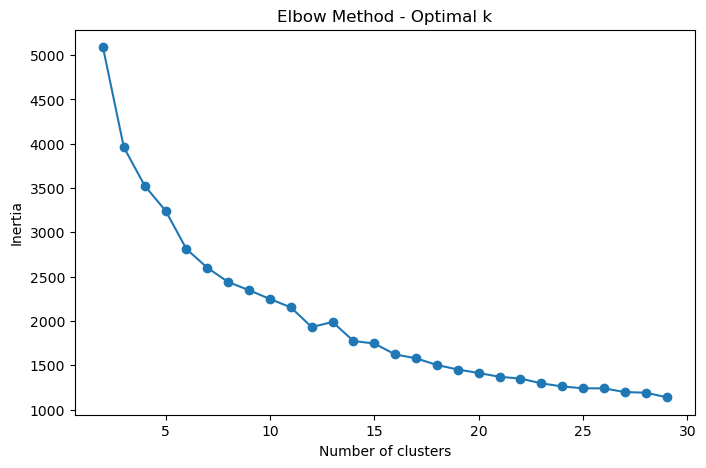

In [34]:
# K-Means Clustering

# Select relevant features
features = ['Income', 'MntWines', 'MntGoldProds', 'NumDealsPurchases', 'AcceptedCmp1', 'NumWebPurchases']
X = filtered_df[features]

#Determine optimal number of clusters using Elbow Method
wcss = []
for i in range(2,30): # different values of k from 2 to 30
    kmeans = KMeans(n_clusters= i)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_) 
    plt.figure(figsize=(8, 5))
plt.plot(range(2,30), wcss, marker='o')
plt.title('Elbow Method - Optimal k')
plt.xlabel('Number of clusters')
plt.ylabel('Inertia')
plt.show()

Silhouette Score for k=2: 0.44


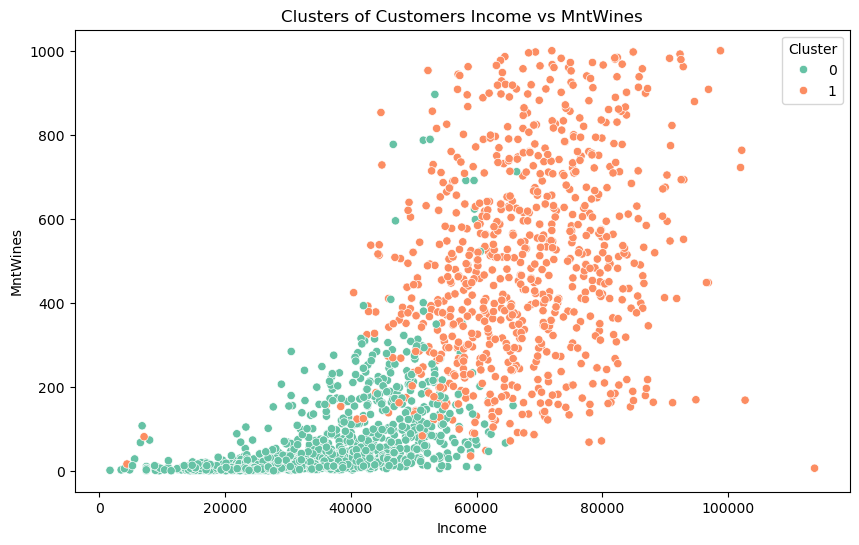

In [37]:
# Based on elbow plot, assume optimal k = 2
k_optimal = 2
kmeans = KMeans(n_clusters=k_optimal, random_state=42)
kmeans.fit(X_scaled)

# Add cluster labels to dataset
filtered_df['Cluster'] = kmeans.labels_

# Silhouette Score
score = silhouette_score(X_scaled, kmeans.labels_)
print(f'Silhouette Score for k={k_optimal}: {score:.2f}')

# Visualize clusters (Income vs MntWines)
plt.figure(figsize=(10, 6))
sns.scatterplot(x=filtered_df['Income'], y=filtered_df['MntWines'], hue=filtered_df['Cluster'], palette='Set2')
plt.title('Clusters of Customers Income vs MntWines')
plt.xlabel('Income')
plt.ylabel('MntWines')
plt.legend(title='Cluster')
plt.show()

Silhouette Score for k=2: 0.44


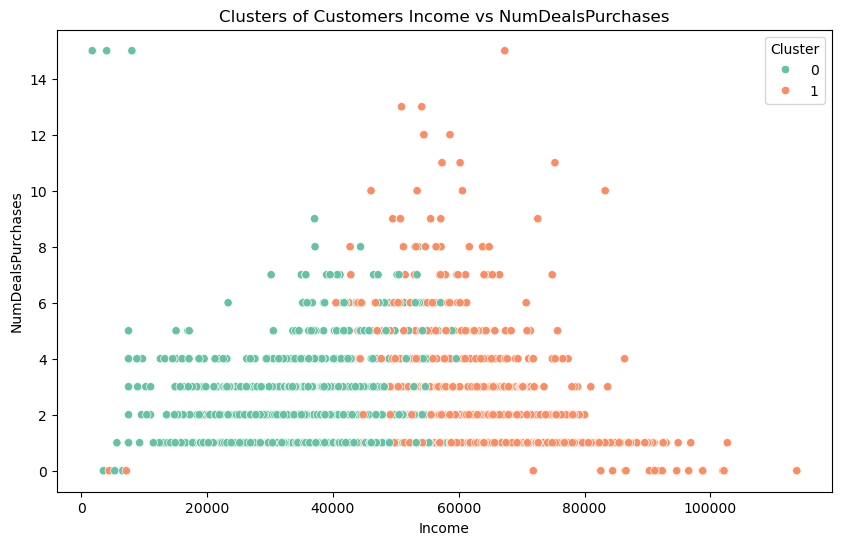

In [42]:
# Based on elbow plot, assume optimal k = 2
k_optimal = 2
kmeans = KMeans(n_clusters=k_optimal, random_state=42)
kmeans.fit(X_scaled)

# Add cluster labels to dataset
filtered_df['Cluster'] = kmeans.labels_

# Silhouette Score
score = silhouette_score(X_scaled, kmeans.labels_)
print(f'Silhouette Score for k={k_optimal}: {score:.2f}')

# Visualize clusters (Income vs 'NumDealsPurchases')
plt.figure(figsize=(10, 6))
sns.scatterplot(x=filtered_df['Income'], y=filtered_df['NumDealsPurchases'], hue=filtered_df['Cluster'], palette='Set2')
plt.title('Clusters of Customers Income vs NumDealsPurchases')
plt.xlabel('Income')
plt.ylabel('NumDealsPurchases')
plt.legend(title='Cluster')
plt.show()

Silhouette Score for k=2: 0.44


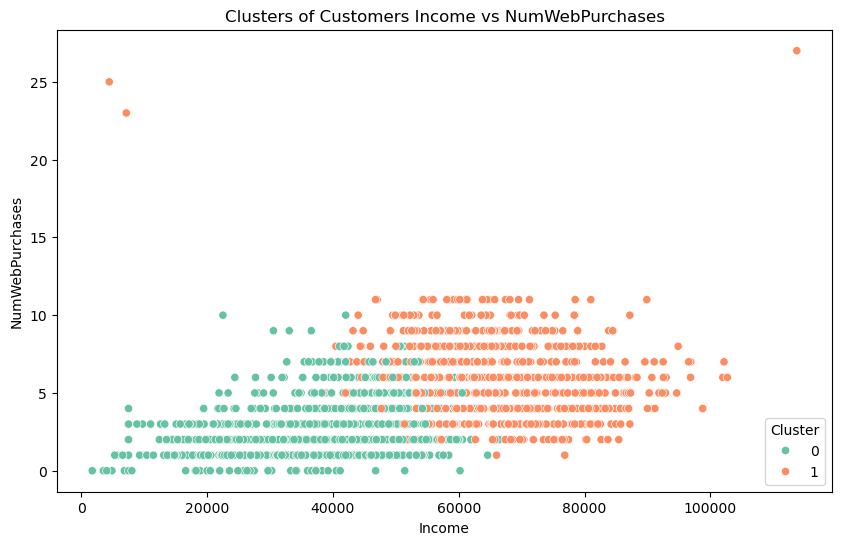

In [44]:
# Based on elbow plot, assume optimal k = 2
k_optimal = 2
kmeans = KMeans(n_clusters=k_optimal, random_state=42)
kmeans.fit(X_scaled)

# Add cluster labels to dataset
filtered_df['Cluster'] = kmeans.labels_

# Silhouette Score
score = silhouette_score(X_scaled, kmeans.labels_)
print(f'Silhouette Score for k={k_optimal}: {score:.2f}')
# Visualize clusters (Income vs 'NumWebPurchases')
plt.figure(figsize=(10, 6))
sns.scatterplot(x=filtered_df['Income'], y=filtered_df['NumWebPurchases'], hue=filtered_df['Cluster'], palette='Set2')
plt.title('Clusters of Customers Income vs NumWebPurchases')
plt.xlabel('Income')
plt.ylabel('NumWebPurchases')
plt.legend(title='Cluster')
plt.show()

In [3]:
# Higher income customers tend to purchase more wines
# Higher income customers tend to have more NumDealsPurchases: Number of purchases made with a discount
# Higher income customers tend to purchase through web